
# XGBoost ile Saatlik Bisiklet Kiralama Sayısının Tahmini

**Proje Türü:** Makine Öğrenmesi – Regresyon

**Kullanılan Algoritma:** XGBoost Regressor

**Programlama Dili:** Python

**Geliştirme Ortamı:** Google Colab



## 1. Problem Tanımı

Bu projenin amacı, Seul'deki bisiklet paylaşım sisteminde saatlik gerçekleşen bisiklet kiralama sayısını makine öğrenmesi yöntemiyle tahmin etmektir. Modelin girdilerini saat, tarih ve meteorolojik koşullar gibi değişkenler oluştururken hedef değişken saatlik gerçekleşen kiralama sayısıdır. Bisiklet kiralama sayısının tahmin edilmesi, bisikletlerin istasyonlara dağıtılması ve operasyonel kaynakların planlanması açısından önem taşımaktadır. Bu doğrultuda XGBoost regresyon algoritması kullanılarak bir tahmin modeli geliştirilecek ve modelin başarısı uygun performans metrikleriyle değerlendirilecektir.



## 2. Veri Setinin Tanıtılması

Bu projede UCI Machine Learning Repository üzerinden erişilebilen "Seoul Bike Sharing Demand" veri seti kullanılmaktadır.

Veri seti, Seul'deki bisiklet paylaşım sistemine ait saatlik kiralama kayıtlarını ve bu saatlerdeki meteorolojik koşulları içermektedir.

- **Veri Kaynağı:** UCI Machine Learning Repository
- **Veri Seti:** Seoul Bike Sharing Demand
- **Gözlem Sayısı:** 8.760
- **Girdi Değişkeni Sayısı:** 13
- **Toplam Değişken Sayısı:** 14
- **Hedef Değişken:** Rented Bike Count
- **Problem Türü:** Regresyon

Veri setinde saat, sıcaklık, nem, rüzgâr hızı, görüş mesafesi, yağış miktarı, mevsim ve tatil durumu gibi değişkenler bulunmaktadır.

**Veri Seti Bağlantısı:**
https://archive.ics.uci.edu/dataset/560/seoul+bike+sharing+demand


In [1]:

%pip install -q ucimlrepo


In [2]:

from ucimlrepo import fetch_ucirepo
import pandas as pd

# Veri setini UCI üzerinden yükleme
bike_dataset = fetch_ucirepo(id=560)

# Veri setini DataFrame olarak oluşturma
df = bike_dataset.data.original.copy()

# Veri setinin boyutu
print("Veri setinin boyutu:", df.shape)

# Sütun isimleri
print("\nSütun isimleri:")
print(df.columns.tolist())

# İlk 5 gözlem
display(df.head())

# Hedef değişken kontrolü
print("\nHedef değişken mevcut mu?",
      "Rented Bike Count" in df.columns)


Veri setinin boyutu: (8760, 14)

Sütun isimleri:
['Date', 'Rented Bike Count', 'Hour', 'Temperature', 'Humidity', 'Wind speed', 'Visibility', 'Dew point temperature', 'Solar Radiation', 'Rainfall', 'Snowfall', 'Seasons', 'Holiday', 'Functioning Day']


,Date,Rented Bike Count,Hour,Temperature,Humidity,Wind speed,Visibility,Dew point temperature,Solar Radiation,Rainfall,Snowfall,Seasons,Holiday,Functioning Day
0,1/12/2017,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
1,1/12/2017,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
2,1/12/2017,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes
3,1/12/2017,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
4,1/12/2017,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes



Hedef değişken mevcut mu? True


In [3]:

# Veri setinin genel yapısı
df.info()

# Değişken bazında özet tablo
ozet = pd.DataFrame({
    "Veri Tipi": df.dtypes,
    "Eksik Değer Sayısı": df.isnull().sum(),
    "Benzersiz Değer Sayısı": df.nunique()
})

display(ozet)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Date                   8760 non-null   object 
 1   Rented Bike Count      8760 non-null   int64  
 2   Hour                   8760 non-null   int64  
 3   Temperature            8760 non-null   float64
 4   Humidity               8760 non-null   int64  
 5   Wind speed             8760 non-null   float64
 6   Visibility             8760 non-null   int64  
 7   Dew point temperature  8760 non-null   float64
 8   Solar Radiation        8760 non-null   float64
 9   Rainfall               8760 non-null   float64
 10  Snowfall               8760 non-null   float64
 11  Seasons                8760 non-null   object 
 12  Holiday                8760 non-null   object 
 13  Functioning Day        8760 non-null   object 
dtypes: float64(6), int64(4), object(4)
memory usage: 958.3+ 

,Veri Tipi,Eksik Değer Sayısı,Benzersiz Değer Sayısı
Date,object,0,365
Rented Bike Count,int64,0,2166
Hour,int64,0,24
Temperature,float64,0,546
Humidity,int64,0,90
Wind speed,float64,0,65
Visibility,int64,0,1789
Dew point temperature,float64,0,556
Solar Radiation,float64,0,345
Rainfall,float64,0,61



### 2.1. Veri Yapısının İncelenmesi

Veri seti 8.760 gözlem ve 14 değişkenden oluşmaktadır. Değişkenlerin 10'u sayısal, 4'ü ise object veri tipindedir.

Yapılan incelemede hiçbir değişkende eksik değer bulunmadığı görülmüştür. Bu nedenle eksik değer doldurma işlemine ihtiyaç duyulmamaktadır.

Date değişkeni metin formatında tutulduğundan ilerleyen aşamalarda tarih formatına dönüştürülecektir. Seasons, Holiday ve Functioning Day değişkenleri kategorik özellikler taşımaktadır.

Hedef değişkenimiz Rented Bike Count olup saatlik gerçekleşen bisiklet kiralama sayısını ifade etmektedir.



## 3. Veri Keşfi (Exploratory Data Analysis - EDA)

Bu bölümde bisiklet kiralama sayılarını etkileyebilecek değişkenler incelenecek ve verideki örüntüler görselleştirilecektir.

### 3.1. Saatlere Göre Ortalama Bisiklet Kiralama Sayısı

Günün farklı saatlerinde gerçekleşen ortalama bisiklet kiralama sayılarını inceleyerek saat ile kiralama sayısı arasındaki ilişkiyi değerlendireceğiz.


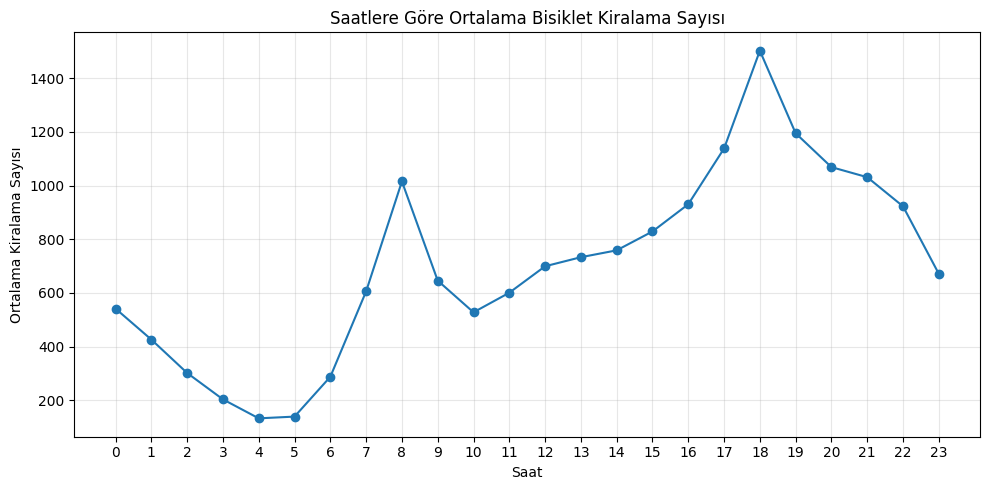

In [4]:

import matplotlib.pyplot as plt

# Saatlere göre ortalama kiralama sayısını hesaplama
saatlik_ortalama = df.groupby("Hour")["Rented Bike Count"].mean()

# Grafik oluşturma
plt.figure(figsize=(10, 5))

plt.plot(
    saatlik_ortalama.index,
    saatlik_ortalama.values,
    marker="o"
)

plt.title("Saatlere Göre Ortalama Bisiklet Kiralama Sayısı")
plt.xlabel("Saat")
plt.ylabel("Ortalama Kiralama Sayısı")
plt.xticks(range(24))
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()



#### Grafik 1 - Bulgular ve Yorum

Saatlere göre ortalama bisiklet kiralama sayıları incelendiğinde, kiralamaların gün içerisinde belirgin biçimde değiştiği görülmektedir.

En yüksek ortalama kiralama sayısı yaklaşık 1.500 ile saat 18.00'de gerçekleşirken, saat 08.00'de de yaklaşık 1.020 kiralama ile ikinci bir yoğunluk gözlenmektedir. En düşük ortalama kiralama sayıları ise 04.00–05.00 saatleri arasındadır.

Sabah ve akşam saatlerinde gözlenen artışların işe ve okula gidiş-dönüş saatleriyle ilişkili olabileceği düşünülmektedir.

Bu bulgular, saat değişkeninin bisiklet kiralama sayısını tahmin etmek açısından önemli bir açıklayıcı değişken olabileceğini göstermektedir.



### 3.2. Sıcaklık ile Bisiklet Kiralama Sayısı Arasındaki İlişki

Bu analizde hava sıcaklığı ile saatlik bisiklet kiralama sayısı arasındaki ilişki incelenmektedir. Sıcaklığın kiralama sayılarıyla nasıl bir ilişki gösterdiğini değerlendirmek amacıyla saçılım grafiği kullanılacaktır.


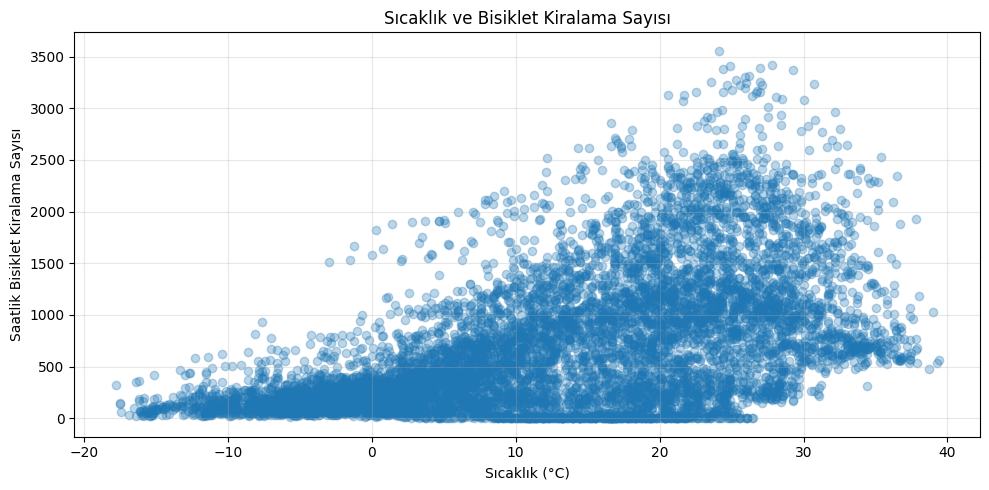

In [5]:

# Sıcaklık ve kiralama sayısı ilişkisi
plt.figure(figsize=(10, 5))

plt.scatter(
    df["Temperature"],
    df["Rented Bike Count"],
    alpha=0.3
)

plt.title("Sıcaklık ve Bisiklet Kiralama Sayısı")
plt.xlabel("Sıcaklık (°C)")
plt.ylabel("Saatlik Bisiklet Kiralama Sayısı")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()



#### Grafik 2 - Bulgular ve Yorum

Sıcaklık ile saatlik bisiklet kiralama sayısı arasındaki ilişki incelendiğinde, sıcaklık arttıkça kiralama sayısının genel olarak artma eğiliminde olduğu görülmektedir.

Özellikle 20–30°C aralığında yüksek kiralama sayılarına daha sık rastlanmaktadır. Ancak çok yüksek sıcaklıklarda bu artışın devam etmediği gözlenmektedir. Bu durum, sıcaklık ile kiralama sayısı arasında doğrusal olmayan bir ilişki olabileceğini düşündürmektedir.

Aynı sıcaklık değerlerinde farklı kiralama sayılarının gözlenmesi, sıcaklık dışında başka değişkenlerin de kiralama sayısıyla ilişkili olabileceğini göstermektedir.

Bu bulgular, doğrusal olmayan ilişkileri modelleyebilen XGBoost algoritmasının tercih edilmesini desteklemektedir. Bununla birlikte ilişkinin yapısı ve modelin tahmin başarısı sonraki aşamalarda değerlendirilecektir.



### 3.3. Mevsimlere Göre Ortalama Bisiklet Kiralama Sayısı

Bu analizde mevsimlere göre ortalama saatlik bisiklet kiralama sayıları karşılaştırılacaktır.

Mevsimsel değişimlerin bisiklet kiralama davranışıyla ilişkisini incelemek amacıyla sütun grafiği kullanılacaktır.


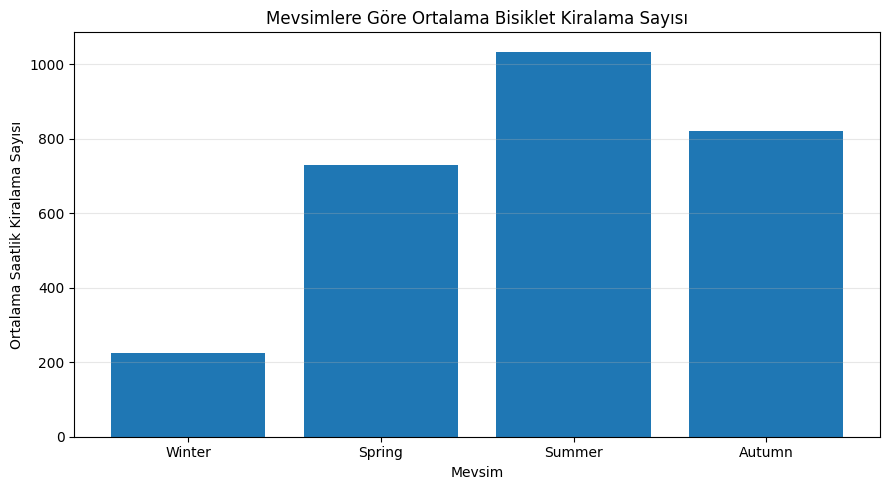

,Ortalama Kiralama Sayısı
Seasons,
Winter,225.541204
Spring,730.031250
Summer,1034.073370
Autumn,819.597985


In [6]:

# Mevsimlere göre ortalama kiralama sayısı
mevsim_ortalamalari = df.groupby("Seasons")["Rented Bike Count"].mean()

# Mevsimleri kronolojik sıraya koyma
mevsim_sirasi = ["Winter", "Spring", "Summer", "Autumn"]
mevsim_ortalamalari = mevsim_ortalamalari.reindex(mevsim_sirasi)

# Sütun grafiği
plt.figure(figsize=(9, 5))

plt.bar(
    mevsim_ortalamalari.index,
    mevsim_ortalamalari.values
)

plt.title("Mevsimlere Göre Ortalama Bisiklet Kiralama Sayısı")
plt.xlabel("Mevsim")
plt.ylabel("Ortalama Saatlik Kiralama Sayısı")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Ortalama değerleri tablo olarak gösterme
display(mevsim_ortalamalari.to_frame("Ortalama Kiralama Sayısı"))



#### Grafik 3 - Bulgular ve Yorum

Mevsimlere göre ortalama saatlik bisiklet kiralama sayıları incelendiğinde, mevsimler arasında belirgin farklılıklar olduğu görülmektedir.

En yüksek ortalama kiralama sayısı 1.034,07 ile yaz mevsiminde, en düşük ortalama ise 225,54 ile kış mevsiminde gerçekleşmiştir. İlkbaharda ortalama 730,03, sonbaharda ise 819,60 bisiklet kiralanmıştır.

Yaz aylarında kiralama sayılarının yüksek olması, hava koşullarının bisiklet kullanımı için daha elverişli olmasıyla ilişkili olabilir. Kış aylarındaki düşük kiralama sayıları ise soğuk hava koşullarından etkilenmiş olabilir.

Bu sonuçlar, mevsim değişkeninin kiralama sayısını tahmin etmede yararlı olabileceğini göstermektedir. Ancak mevsimlerin etkisinin diğer değişkenlerden bağımsız olduğu sonucuna varılamaz.




### 3.4. Hedef Değişkenin ve Sistemin Çalışma Durumunun İncelenmesi

Bu bölümde saatlik bisiklet kiralama sayısının dağılımı ve sistemin çalışmadığı günlerdeki kiralama kayıtları incelenmektedir.

Amaç, sıfır kiralama değerlerinin sistemin çalışma durumuyla ilişkisini değerlendirmek ve modelleme öncesinde veri kalitesini kontrol etmektir.


In [7]:

# Hedef değişkenin betimsel istatistikleri
print("Kiralama sayısının özeti:")
display(df["Rented Bike Count"].describe())

# Sıfır kiralama gözlemleri
print("Sıfır kiralama sayısı:",
      (df["Rented Bike Count"] == 0).sum())

# Sistemin çalışma durumuna göre kiralama analizi
calisma_durumu = df.groupby("Functioning Day")["Rented Bike Count"].agg(
    Gozlem_Sayisi="count",
    Ortalama_Kiralama="mean",
    Sifir_Kiralama_Sayisi=lambda x: (x == 0).sum()
)

display(calisma_durumu)

# Aynı tarih ve saatin tekrar edip etmediğini kontrol etme
print("Tekrarlanan tarih-saat sayısı:",
      df.duplicated(subset=["Date", "Hour"]).sum())


Kiralama sayısının özeti:


,Rented Bike Count
count,8760.000000
mean,704.602055
std,644.997468
min,0.000000
25%,191.000000
50%,504.500000
75%,1065.250000
max,3556.000000


Sıfır kiralama sayısı: 295


,Gozlem_Sayisi,Ortalama_Kiralama,Sifir_Kiralama_Sayisi
Functioning Day,,,
No,295,0.000000,295
Yes,8465,729.156999,0


Tekrarlanan tarih-saat sayısı: 0



#### 3.4. Bulgular ve Yorum

Hedef değişkenin betimsel istatistikleri incelendiğinde, saatlik ortalama kiralama sayısının 704,60, medyanın ise 504,5 olduğu görülmektedir. Kiralama sayıları 0 ile 3.556 arasında değişmekte ve standart sapma yaklaşık 645 olarak hesaplanmaktadır.

Veri setinde toplam 295 sıfır kiralama gözlemi bulunmaktadır. Functioning Day değişkeniyle yapılan karşılaştırmada, bu gözlemlerin tamamının sistemin çalışmadığı saatlere ait olduğu belirlenmiştir.

Sistemin çalıştığı 8.465 saatlik gözlemde ortalama kiralama sayısı yaklaşık 729,16'dır.

Ayrıca Date ve Hour değişkenlerine göre tekrarlanan kayıt bulunmamıştır.

Bu bulgular, sistemin çalışma durumunun modelleme sürecinde dikkate alınması gerektiğini göstermektedir.



## 4. Veri Ön İşleme (Data Preprocessing)

Bu bölümde veri seti, XGBoost regresyon modelinin eğitimi için hazırlanacaktır. Veri temizleme, tarih değişkeninin dönüştürülmesi, kategorik değişkenlerin kodlanması ve veri bölme işlemleri ele alınacaktır.

### 4.1. Sistemin Çalışmadığı Gözlemlerin Ayrılması

Veri keşfi aşamasında, sistemin çalışmadığı 295 saatlik gözlemin tamamında kiralama sayısının sıfır olduğu belirlenmiştir.

Bu sıfır değerleri düşük talepten değil, sistemin hizmet vermemesinden kaynaklanmaktadır. Projenin amacı sistemin aktif olduğu zamanlardaki gerçekleşen kiralama sayısını tahmin etmek olduğundan, Functioning Day değeri "No" olan gözlemler modelleme veri setinden çıkarılacaktır.

Bu işlem sonrasında modelleme için 8.465 gözlem kalması beklenmektedir.


In [8]:

# Sistemin çalıştığı gözlemleri seçme
df_model = df[df["Functioning Day"] == "Yes"].copy()

# Orijinal ve filtrelenmiş veri boyutları
print("Orijinal veri boyutu:", df.shape)
print("Filtrelenmiş veri boyutu:", df_model.shape)

# Çıkarılan gözlem sayısı
print("Çıkarılan gözlem sayısı:", len(df) - len(df_model))

# Sistem çalışma durumunu kontrol etme
print("Çalışma durumu:", df_model["Functioning Day"].unique())

# Sıfır kiralama kontrolü
print("Kalan sıfır kiralama sayısı:",
      (df_model["Rented Bike Count"] == 0).sum())


Orijinal veri boyutu: (8760, 14)
Filtrelenmiş veri boyutu: (8465, 14)
Çıkarılan gözlem sayısı: 295
Çalışma durumu: ['Yes']
Kalan sıfır kiralama sayısı: 0



### 4.2. Tarih Değişkeninin Dönüştürülmesi

Date değişkeni başlangıçta object veri tipinde bulunmaktadır. Tarih bilgisinin doğru şekilde işlenebilmesi ve ilerleyen aşamalarda zamana dayalı yeni değişkenler oluşturulabilmesi için datetime formatına dönüştürülecektir.

Ayrıca gözlemler tarih ve saat bilgilerine göre kronolojik olarak sıralanacaktır. Bu sıralama, zaman bağımlı verilerde eğitim ve test kümelerinin doğru oluşturulması açısından önemlidir.


In [9]:

# Date değişkenini datetime formatına dönüştürme
df_model["Date"] = pd.to_datetime(
    df_model["Date"],
    format="%d/%m/%Y"
)

# Gözlemleri tarih ve saate göre sıralama
df_model = df_model.sort_values(
    by=["Date", "Hour"]
).reset_index(drop=True)

# Dönüşümü kontrol etme
print("Date veri tipi:", df_model["Date"].dtype)

print("İlk tarih:", df_model["Date"].min())
print("Son tarih:", df_model["Date"].max())

# İlk 5 gözlemi inceleme
display(df_model[["Date", "Hour", "Rented Bike Count"]].head())


Date veri tipi: datetime64[ns]
İlk tarih: 2017-12-01 00:00:00
Son tarih: 2018-11-30 00:00:00


,Date,Hour,Rented Bike Count
0,2017-12-01,0,254
1,2017-12-01,1,204
2,2017-12-01,2,173
3,2017-12-01,3,107
4,2017-12-01,4,78



### 4.3. Yeni Değişkenlerin Oluşturulması (Feature Engineering)

Tarih değişkeninden modelin kullanabileceği ek özellikler elde edilmiştir.

Bu kapsamda Month (ay), DayOfWeek (haftanın günü) ve IsWeekend (hafta sonu göstergesi) değişkenleri oluşturulacaktır.

Bu değişkenler, bisiklet kiralama sayılarının aylara, haftanın günlerine ve hafta sonu durumuna göre değişebilecek örüntülerini modelin öğrenmesine yardımcı olabilir.


In [10]:

# Tarih değişkeninden ay bilgisini çıkarma
df_model["Month"] = df_model["Date"].dt.month

# Haftanın gününü belirleme
df_model["DayOfWeek"] = df_model["Date"].dt.dayofweek

# Hafta sonu değişkeni oluşturma
df_model["IsWeekend"] = (df_model["DayOfWeek"] >= 5).astype(int)

# Oluşturulan değişkenleri kontrol etme
display(
    df_model[["Date", "Month", "DayOfWeek", "IsWeekend"]]
    .drop_duplicates()
    .head(7)
)

print("Güncel veri seti boyutu:", df_model.shape)


,Date,Month,DayOfWeek,IsWeekend
0,2017-12-01,12,4,0
24,2017-12-02,12,5,1
48,2017-12-03,12,6,1
72,2017-12-04,12,0,0
96,2017-12-05,12,1,0
120,2017-12-06,12,2,0
144,2017-12-07,12,3,0


Güncel veri seti boyutu: (8465, 17)



### 4.4. Aykırı Değer Analizi (Outlier Detection)

Bu aşamada hedef değişken olan Rented Bike Count içerisindeki olası aykırı değerler incelenecektir.

Aykırı değerlerin belirlenmesi amacıyla çeyrekler açıklığı (Interquartile Range - IQR) yöntemi ve kutu grafiği (boxplot) kullanılacaktır.

Ancak yüksek kiralama sayıları gerçek yoğunluk dönemlerini temsil edebileceğinden, tespit edilen gözlemler doğrudan veri setinden çıkarılmayacaktır.


Q1: 214.0
Q3: 1084.0
IQR: 870.0
Alt sınır: -1091.0
Üst sınır: 2389.0
Potansiyel aykırı değer sayısı: 152
Potansiyel aykırı değer oranı (%): 1.8


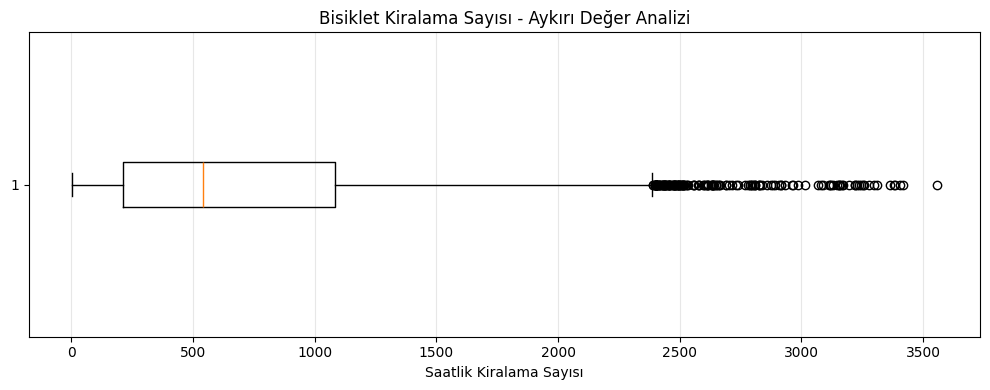

In [11]:

# Hedef değişkenin çeyrekliklerini hesaplama
Q1 = df_model["Rented Bike Count"].quantile(0.25)
Q3 = df_model["Rented Bike Count"].quantile(0.75)

# Çeyrekler açıklığı (IQR)
IQR = Q3 - Q1

# Aykırı değer sınırları
alt_sinir = Q1 - 1.5 * IQR
ust_sinir = Q3 + 1.5 * IQR

# Potansiyel aykırı değerleri belirleme
aykiri_maskesi = (
    (df_model["Rented Bike Count"] < alt_sinir) |
    (df_model["Rented Bike Count"] > ust_sinir)
)

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Alt sınır:", alt_sinir)
print("Üst sınır:", ust_sinir)

print("Potansiyel aykırı değer sayısı:", aykiri_maskesi.sum())

print("Potansiyel aykırı değer oranı (%):",
      round(aykiri_maskesi.mean() * 100, 2))

# Kutu grafiği
plt.figure(figsize=(10, 4))

plt.boxplot(
    df_model["Rented Bike Count"],
    vert=False
)

plt.title("Bisiklet Kiralama Sayısı - Aykırı Değer Analizi")
plt.xlabel("Saatlik Kiralama Sayısı")
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()



#### 4.4. Aykırı Değer Analizi - Bulgular ve Yorum

IQR yöntemi kullanılarak yapılan analizde birinci çeyreklik 214, üçüncü çeyreklik 1.084 ve çeyrekler açıklığı 870 olarak hesaplanmıştır.

Alt sınır -1.091, üst sınır ise 2.389 olarak belirlenmiştir. Bu sınırların dışında kalan 152 gözlem, veri setinin yaklaşık %1,8'ini oluşturmaktadır.

Potansiyel aykırı değerlerin tamamı yüksek kiralama sayılarından kaynaklanmaktadır. Bu gözlemler gerçek yoğunluk dönemlerini temsil edebileceğinden veri setinden çıkarılmamıştır.

Model değerlendirme aşamasında yüksek kiralama sayılarındaki tahmin hataları ayrıca incelenecektir.



### 4.5. Kategorik Değişkenlerin Kodlanması (Encoding)

Veri setinde bulunan Seasons ve Holiday değişkenleri kategorik yapıdadır. Bu değişkenler, XGBoost modelinde kullanılabilmeleri amacıyla One-Hot Encoding yöntemiyle sayısal değişkenlere dönüştürülecektir.

One-Hot Encoding yöntemi, kategoriler arasında yapay bir büyüklük veya sıralama ilişkisi oluşturmadan her kategoriyi ayrı bir ikili değişkenle temsil etmektedir.

Ayrıca yalnızca sistemin çalıştığı gözlemlerle çalışıldığından, bütün gözlemlerde aynı değeri alan Functioning Day değişkeni modelleme veri setinden çıkarılacaktır.


In [12]:

# Kategorik değişkenlerin mevcut değerlerini inceleme
print("Seasons kategorileri:")
print(df_model["Seasons"].unique())

print("\nHoliday kategorileri:")
print(df_model["Holiday"].unique())

# One-Hot Encoding uygulama
df_encoded = pd.get_dummies(
    df_model,
    columns=["Seasons", "Holiday"],
    dtype=int
)

# Sabit değer taşıyan değişkeni çıkarma
df_encoded = df_encoded.drop(columns=["Functioning Day"])

# Encoding sonrası oluşan sütunları inceleme
print("\nEncoding sonrası sütunlar:")
print(df_encoded.columns.tolist())

print("\nVeri setinin yeni boyutu:", df_encoded.shape)

# Kategorik dönüşümü kontrol etme
display(df_encoded.filter(regex="^(Seasons_|Holiday_)").head())


Seasons kategorileri:
['Winter' 'Spring' 'Summer' 'Autumn']

Holiday kategorileri:
['No Holiday' 'Holiday']

Encoding sonrası sütunlar:
['Date', 'Rented Bike Count', 'Hour', 'Temperature', 'Humidity', 'Wind speed', 'Visibility', 'Dew point temperature', 'Solar Radiation', 'Rainfall', 'Snowfall', 'Month', 'DayOfWeek', 'IsWeekend', 'Seasons_Autumn', 'Seasons_Spring', 'Seasons_Summer', 'Seasons_Winter', 'Holiday_Holiday', 'Holiday_No Holiday']

Veri setinin yeni boyutu: (8465, 20)


,Seasons_Autumn,Seasons_Spring,Seasons_Summer,Seasons_Winter,Holiday_Holiday,Holiday_No Holiday
0,0,0,0,1,0,1
1,0,0,0,1,0,1
2,0,0,0,1,0,1
3,0,0,0,1,0,1
4,0,0,0,1,0,1



#### 4.5. Encoding Sonuçları

Seasons değişkenindeki dört kategori ve Holiday değişkenindeki iki kategori, One-Hot Encoding yöntemiyle toplam altı ikili değişkene dönüştürülmüştür.

Bütün gözlemlerde aynı değeri alan Functioning Day değişkeni modelleme verisinden çıkarılmıştır.

Bu işlemler sonucunda veri seti 8.465 gözlem ve 20 sütundan oluşmaktadır.



### 4.6. Girdi ve Hedef Değişkenlerin Ayrılması

Modelin girdileri (X) ile tahmin edilmesi amaçlanan hedef değişken (y) birbirinden ayrılacaktır.

Hedef değişken olarak Rented Bike Count seçilmiştir. Ham Date değişkeni model girdilerinden çıkarılacak, ancak kronolojik veri bölme işleminde kullanılmak üzere korunacaktır.

Bu işlem, hedef değişkenin yanlışlıkla model girdilerine dahil edilmesini önlemektedir.


In [13]:

# Hedef değişken
y = df_encoded["Rented Bike Count"].copy()

# Girdi değişkenleri
X = df_encoded.drop(
    columns=["Date", "Rented Bike Count"]
).copy()

# Kronolojik bölme için tarihleri saklama
dates = df_encoded["Date"].copy()

# Boyutları kontrol etme
print("X boyutu:", X.shape)
print("y boyutu:", y.shape)

# Girdi değişkenlerini gösterme
print("\nModelde kullanılacak değişkenler:")
print(X.columns.tolist())

# Sayısal olmayan girdi var mı?
print("\nSayısal olmayan girdiler:")
print(X.select_dtypes(exclude="number").columns.tolist())


X boyutu: (8465, 18)
y boyutu: (8465,)

Modelde kullanılacak değişkenler:
['Hour', 'Temperature', 'Humidity', 'Wind speed', 'Visibility', 'Dew point temperature', 'Solar Radiation', 'Rainfall', 'Snowfall', 'Month', 'DayOfWeek', 'IsWeekend', 'Seasons_Autumn', 'Seasons_Spring', 'Seasons_Summer', 'Seasons_Winter', 'Holiday_Holiday', 'Holiday_No Holiday']

Sayısal olmayan girdiler:
[]



#### 4.6. Girdi ve Hedef Değişkenlerin Ayrılması - Sonuçlar

Hedef değişken (Rented Bike Count) ile girdi değişkenleri birbirinden ayrılmıştır.

Modelde 8.465 gözlem ve 18 sayısal girdi değişkeni kullanılacaktır. Sayısal olmayan girdi bulunmadığı doğrulanmıştır.

### 4.7. Eğitim, Doğrulama ve Test Verilerinin Ayrılması

Veri seti saatlik gözlemlerden oluştuğu için rastgele bölme yerine kronolojik veri bölme yöntemi tercih edilmiştir.

Veriler tarihler esas alınarak yaklaşık %70 eğitim (train), %15 doğrulama (validation) ve %15 test kümelerine ayrılacaktır.

Eğitim kümesi modelin öğrenilmesi, doğrulama kümesi hiperparametrelerin belirlenmesi ve test kümesi nihai tahmin performansının değerlendirilmesi amacıyla kullanılacaktır.

Aynı tarihe ait gözlemler farklı kümelere dağıtılmayacaktır.


In [14]:

# Kronolojik sıradaki benzersiz tarihleri alma
unique_dates = dates.drop_duplicates().sort_values().reset_index(drop=True)

# Bölme noktalarını belirleme
train_end = int(len(unique_dates) * 0.70)
val_end = int(len(unique_dates) * 0.85)

# Tarihlere göre maskeler oluşturma
train_mask = dates.isin(unique_dates.iloc[:train_end])
val_mask = dates.isin(unique_dates.iloc[train_end:val_end])
test_mask = dates.isin(unique_dates.iloc[val_end:])

# Girdi ve hedef değişkenleri ayırma
X_train, y_train = X.loc[train_mask], y.loc[train_mask]
X_val, y_val = X.loc[val_mask], y.loc[val_mask]
X_test, y_test = X.loc[test_mask], y.loc[test_mask]

# Küme boyutlarını gösterme
print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

# Tarih aralıklarını kontrol etme
for isim, maske in [
    ("Train", train_mask),
    ("Validation", val_mask),
    ("Test", test_mask)
]:
    print(
        f"{isim} tarih aralığı:",
        dates.loc[maske].min().date(),
        "-",
        dates.loc[maske].max().date()
    )

# Gözlem kaybı olup olmadığını kontrol etme
print("\nToplam gözlem:",
      len(X_train) + len(X_val) + len(X_test))


Train: (5928, 18) (5928,)
Validation: (1272, 18) (1272,)
Test: (1265, 18) (1265,)
Train tarih aralığı: 2017-12-01 - 2018-08-06
Validation tarih aralığı: 2018-08-07 - 2018-10-03
Test tarih aralığı: 2018-10-05 - 2018-11-30

Toplam gözlem: 8465



#### 4.7. Veri Bölme Sonuçları

Kronolojik veri bölme işlemi sonucunda 5.928 gözlem eğitim, 1.272 gözlem doğrulama ve 1.265 gözlem test kümesine ayrılmıştır.

Her kümede 18 girdi değişkeni bulunmaktadır. Toplam 8.465 gözlemin tamamı korunmuştur.

Eğitim dönemi 1 Aralık 2017 – 6 Ağustos 2018, doğrulama dönemi 7 Ağustos – 3 Ekim 2018 ve test dönemi 5 Ekim – 30 Kasım 2018 tarihlerini kapsamaktadır.

Kronolojik ayrım, modelin geçmiş gözlemlerle eğitilip daha sonraki dönemlerde değerlendirilmesini sağlamaktadır. Bununla birlikte veri setinin yalnızca bir yıllık olması nedeniyle mevsimlerin kümelerdeki temsili ayrıca incelenecektir.


In [15]:

# Train, Validation ve Test kümelerinin mevsim dağılımları
for isim, maske in [
    ("Train", train_mask),
    ("Validation", val_mask),
    ("Test", test_mask)
]:
    print(f"\n{isim} mevsim dağılımı:")

    print(
        df_model.loc[maske, "Seasons"]
        .value_counts()
        .reindex(
            ["Winter", "Spring", "Summer", "Autumn"],
            fill_value=0
        )
    )

# 4 Ekim 2018 tarihinde filtrelenmiş gözlem var mı?
print("\n4 Ekim 2018 gözlem sayısı:",
      (dates == pd.Timestamp("2018-10-04")).sum())



Train mevsim dağılımı:
Seasons
Winter    2160
Spring    2160
Summer    1608
Autumn       0
Name: count, dtype: int64

Validation mevsim dağılımı:
Seasons
Winter      0
Spring      0
Summer    600
Autumn    672
Name: count, dtype: int64

Test mevsim dağılımı:
Seasons
Winter       0
Spring       0
Summer       0
Autumn    1265
Name: count, dtype: int64

4 Ekim 2018 gözlem sayısı: 0



#### 4.7.1. Mevsim Dağılımının Değerlendirilmesi

Eğitim, doğrulama ve test kümelerinin mevsim dağılımları incelendiğinde, eğitim kümesinin kış, ilkbahar ve yaz gözlemlerinden oluştuğu; sonbahar gözlemi içermediği görülmüştür.

Doğrulama kümesi yaz ve sonbahar, test kümesi ise yalnızca sonbahar gözlemlerini içermektedir.

Bu durum, veri setinin yalnızca bir yıllık olması nedeniyle modelin farklı mevsimlere genelleme başarısı açısından bir sınırlılık oluşturmaktadır.

Kronolojik bölme korunacaktır. Hiperparametre seçiminden sonra nihai model eğitim ve doğrulama verileri birleştirilerek yeniden eğitilecektir. Böylece sonbaharın başlangıcındaki gözlemler de son modelin eğitimine dahil edilecektir.

Nihai test sonuçları yalnızca test dönemindeki sonbahar gözlemleri için yorumlanacaktır.



### 4.8. Ölçeklendirme (Scaling)

Bu projede ağaç tabanlı XGBoost regresyon algoritması kullanılmaktadır.

Karar ağaçları, değişkenleri belirli eşik değerlerine göre ayırarak çalıştığından değişkenlerin farklı sayısal ölçeklerde bulunması genellikle model için sorun oluşturmaz.

Bu nedenle StandardScaler veya MinMaxScaler uygulanmasına gerek duyulmamıştır. Girdi değişkenleri mevcut sayısal ölçekleriyle kullanılacaktır.



## 5. Model Seçimi ve Tasarımı

XGBoost, gradient boosting yaklaşımını kullanan, karar ağaçlarına dayalı bir makine öğrenmesi algoritmasıdır. Ağaçları ardışık olarak eğiterek önceki tahminlerdeki hataları azaltmayı amaçlar.

Veri keşfi aşamasında sıcaklık ve kiralama sayısı arasında doğrusal olmayan ilişkiler gözlenmiştir. Ayrıca saat ve mevsim değişkenlerinin kiralama sayısıyla belirgin ilişkiler gösterdiği belirlenmiştir.

XGBoost'un doğrusal olmayan ilişkileri ve değişkenler arasındaki etkileşimleri modelleyebilmesi nedeniyle bu problem için uygun olduğu düşünülmektedir.

### 5.1. Başlangıç Modelinin Oluşturulması

İlk aşamada başlangıç hiperparametreleriyle bir XGBoost regresyon modeli eğitilecektir. Daha sonra validation kümesindeki sonuçlara göre hiperparametreler değerlendirilecektir.


In [16]:

%pip install -q xgboost


In [17]:

from xgboost import XGBRegressor

# Başlangıç XGBoost modelini oluşturma
xgb_model = XGBRegressor(
    objective="reg:squarederror",
    n_estimators=300,
    max_depth=4,
    learning_rate=0.1,
    random_state=42,
    tree_method="hist"
)

# Modeli yalnızca eğitim verisiyle eğitme
xgb_model.fit(X_train, y_train)

print("XGBoost başlangıç modeli başarıyla eğitildi.")
print("Eğitim gözlem sayısı:", len(X_train))
print("Kullanılan değişken sayısı:", X_train.shape[1])


XGBoost başlangıç modeli başarıyla eğitildi.
Eğitim gözlem sayısı: 5928
Kullanılan değişken sayısı: 18



### 5.2. Başlangıç Modelinin Performansının Değerlendirilmesi

Başlangıç XGBoost modelinin tahmin performansı MAE (Mean Absolute Error), RMSE (Root Mean Squared Error) ve R² (Coefficient of Determination) metrikleri kullanılarak değerlendirilecektir.

Modelin eğitim ve doğrulama kümelerindeki sonuçları karşılaştırılarak aşırı öğrenme olup olmadığına ilişkin ilk değerlendirme yapılacaktır.

Test kümesi bu aşamada kullanılmayacak, yalnızca son modelin performansını ölçmek amacıyla saklanacaktır.


In [18]:

import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Eğitim ve doğrulama verileri için tahminler
y_train_pred = xgb_model.predict(X_train)
y_val_pred = xgb_model.predict(X_val)

# Train performans metrikleri
train_mae = mean_absolute_error(y_train, y_train_pred)
train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))
train_r2 = r2_score(y_train, y_train_pred)

# Validation performans metrikleri
val_mae = mean_absolute_error(y_val, y_val_pred)
val_rmse = np.sqrt(mean_squared_error(y_val, y_val_pred))
val_r2 = r2_score(y_val, y_val_pred)

# Sonuçları tablo halinde gösterme
sonuclar = pd.DataFrame({
    "Veri Kümesi": ["Train", "Validation"],
    "MAE": [train_mae, val_mae],
    "RMSE": [train_rmse, val_rmse],
    "R²": [train_r2, val_r2]
})

display(sonuclar.round(4))


,Veri Kümesi,MAE,RMSE,R²
0,Train,71.933,115.8173,0.9670
1,Validation,175.313,252.9270,0.8528



#### 5.2.1. Başlangıç Modeli - Bulgular ve Yorum

Başlangıç XGBoost modelinin eğitim kümesindeki MAE, RMSE ve R² değerleri sırasıyla 71,93; 115,82 ve 0,9670 olarak hesaplanmıştır.

Doğrulama kümesinde ise MAE 175,31, RMSE 252,93 ve R² 0,8528 olarak elde edilmiştir.

Doğrulama kümesindeki R² değeri, modelin daha önce görmediği gözlemlerde de anlamlı bir tahmin performansı gösterdiğini ortaya koymaktadır. Bununla birlikte doğrulama hatalarının eğitim hatalarından belirgin biçimde yüksek olduğu görülmektedir.

Bu farklılık, modelde aşırı öğrenme olasılığını düşündürmektedir. Ancak eğitim verisinin sonbahar gözlemi içermemesi ve doğrulama kümesinin yaz ile sonbahar dönemlerinden oluşması da performans farkına katkıda bulunmuş olabilir.

Bu nedenle modelin hiperparametreleri doğrulama kümesi kullanılarak karşılaştırılacak ve genelleme performansının iyileştirilmesi amaçlanacaktır.

Test kümesi, nihai performans değerlendirmesine kadar kullanılmayacaktır.



### 5.3. Hiperparametre Optimizasyonu (Hyperparameter Tuning)

Başlangıç modelinde eğitim ve doğrulama performansları arasında fark gözlendiğinden, modelin genelleme performansını iyileştirmek amacıyla hiperparametre karşılaştırması yapılacaktır.

Bu kapsamda n_estimators, max_depth ve learning_rate değerleri için dört farklı kombinasyon denenecektir.

Modeller aynı eğitim kümesiyle eğitilecek ve aynı doğrulama kümesi üzerinde MAE, RMSE ve R² metrikleriyle değerlendirilecektir.

Hiperparametre seçiminin temel ölçütü en düşük doğrulama RMSE değeri olacaktır. Test kümesi bu işlem sırasında kullanılmayacaktır.


In [19]:

# Denenecek hiperparametre kombinasyonları
denemeler = [
    ("A - Başlangıç", 300, 4, 0.10),
    ("B - Sığ ağaç", 300, 3, 0.10),
    ("C - Yavaş öğrenme", 500, 4, 0.05),
    ("D - Sığ ve yavaş", 500, 3, 0.05)
]

tuning_sonuclari = []
modeller = {}

for isim, n, depth, lr in denemeler:

    # XGBoost modelini oluşturma
    model = XGBRegressor(
        objective="reg:squarederror",
        n_estimators=n,
        max_depth=depth,
        learning_rate=lr,
        random_state=42,
        tree_method="hist"
    )

    # Modeli eğitim verisiyle eğitme
    model.fit(X_train, y_train)

    # Train ve validation tahminleri
    train_pred = model.predict(X_train)
    val_pred = model.predict(X_val)

    # Sonuçları kaydetme
    tuning_sonuclari.append({
        "Model": isim,
        "Train RMSE": np.sqrt(
            mean_squared_error(y_train, train_pred)
        ),
        "Validation MAE": mean_absolute_error(
            y_val, val_pred
        ),
        "Validation RMSE": np.sqrt(
            mean_squared_error(y_val, val_pred)
        ),
        "Validation R²": r2_score(
            y_val, val_pred
        )
    })

    modeller[isim] = model

# Modelleri doğrulama RMSE değerine göre sıralama
tuning_df = pd.DataFrame(tuning_sonuclari)
tuning_df = tuning_df.sort_values("Validation RMSE")

display(tuning_df.round(4))

# En düşük validation RMSE değerine sahip modeli bulma
en_iyi_model_adi = tuning_df.iloc[0]["Model"]

print("En iyi validation RMSE:", en_iyi_model_adi)


,Model,Train RMSE,Validation MAE,Validation RMSE,Validation R²
0,A - Başlangıç,115.8173,175.3130,252.9270,0.8528
2,C - Yavaş öğrenme,119.1481,181.3625,260.6672,0.8437
1,B - Sığ ağaç,151.2189,191.6514,269.8027,0.8325
3,D - Sığ ve yavaş,157.6729,191.7482,270.0052,0.8323


En iyi validation RMSE: A - Başlangıç



#### 5.3.1. Hiperparametre Optimizasyonu Sonuçları

XGBoost regresyon modeli için dört farklı hiperparametre kombinasyonu denenmiş ve modeller doğrulama kümesindeki performanslarına göre karşılaştırılmıştır.

En düşük doğrulama RMSE değeri 252,93 ile başlangıç modelinde (Model A) elde edilmiştir. Bu modelin MAE değeri 175,31 ve R² değeri 0,8528 olarak hesaplanmıştır.

Ağaç derinliğinin azaltıldığı ve öğrenme oranının düşürüldüğü alternatif modeller, doğrulama performansında iyileşme sağlamamıştır.

Bu nedenle nihai model için n_estimators=300, max_depth=4 ve learning_rate=0.1 hiperparametreleri seçilmiştir.

Hiperparametre seçimi yalnızca doğrulama kümesindeki sonuçlara dayanmaktadır. Denenen kombinasyon sayısının sınırlı olması ve doğrulama kümesinin belirli mevsimleri kapsaması çalışmanın metodolojik sınırlılıkları arasındadır.



### 5.4. Nihai Modelin Eğitilmesi

Hiperparametre karşılaştırması sonucunda en iyi doğrulama performansını sağlayan başlangıç modeli seçilmiştir.

Nihai modelin daha fazla gözlemden öğrenebilmesi amacıyla eğitim ve doğrulama kümeleri birleştirilerek toplam 7.200 gözlemden oluşan yeni bir eğitim kümesi oluşturulacaktır.

Seçilen hiperparametrelerle XGBoost regresyon modeli yeniden eğitilecektir.

Test kümesi, eğitim sürecine dahil edilmeyecek ve yalnızca nihai model performansını değerlendirmek amacıyla kullanılacaktır.


In [20]:

# Train ve Validation kümelerini birleştirme
X_train_val = pd.concat([X_train, X_val]).sort_index()
y_train_val = pd.concat([y_train, y_val]).sort_index()

# Nihai XGBoost modelini oluşturma
final_model = XGBRegressor(
    objective="reg:squarederror",
    n_estimators=300,
    max_depth=4,
    learning_rate=0.1,
    random_state=42,
    tree_method="hist"
)

# Nihai modeli eğitme
final_model.fit(X_train_val, y_train_val)

# Kontroller
print("Nihai model başarıyla eğitildi.")
print("Eğitim gözlem sayısı:", len(X_train_val))
print("Girdi değişkeni sayısı:", X_train_val.shape[1])
print("Test gözlem sayısı:", len(X_test))


Nihai model başarıyla eğitildi.
Eğitim gözlem sayısı: 7200
Girdi değişkeni sayısı: 18
Test gözlem sayısı: 1265



## 6. Nihai Modelin Değerlendirilmesi

### 6.1. Test Performansının Hesaplanması

Hiperparametre optimizasyonu tamamlandıktan sonra seçilen XGBoost modeli, eğitim ve doğrulama kümelerinin birleştirilmesiyle oluşan 7.200 gözlem üzerinde yeniden eğitilmiştir.

Nihai modelin genelleme performansını değerlendirmek amacıyla eğitim ve hiperparametre seçimi süreçlerinde kullanılmayan 1.265 gözlemden oluşan test kümesi kullanılacaktır.

Model performansı MAE, RMSE ve R² metrikleriyle ölçülecektir.

Test kümesi yalnızca sonbahar dönemine ait olduğundan elde edilen sonuçlar öncelikle bu dönemdeki tahmin performansını temsil etmektedir.


In [21]:

# Nihai model ile test tahminleri
y_test_pred = final_model.predict(X_test)

# Test performans metrikleri
test_mae = mean_absolute_error(y_test, y_test_pred)

test_rmse = np.sqrt(
    mean_squared_error(y_test, y_test_pred)
)

test_r2 = r2_score(y_test, y_test_pred)

# Sonuç tablosu
test_sonuclari = pd.DataFrame({
    "Metrik": ["MAE", "RMSE", "R²"],
    "Değer": [test_mae, test_rmse, test_r2]
})

print("Nihai XGBoost Modeli - Test Sonuçları")
display(test_sonuclari.round(4))

# İlk 10 gerçek ve tahmin değerinin karşılaştırılması
tahmin_karsilastirma = pd.DataFrame({
    "Gerçek Kiralama": y_test.to_numpy(),
    "Tahmin Edilen Kiralama": y_test_pred
})

print("\nİlk 10 tahmin:")
display(tahmin_karsilastirma.head(10).round(2))


Nihai XGBoost Modeli - Test Sonuçları


,Metrik,Değer
0,MAE,188.8271
1,RMSE,274.1334
2,R²,0.7531



İlk 10 tahmin:


,Gerçek Kiralama,Tahmin Edilen Kiralama
0,973,957.580017
1,735,726.359985
2,515,523.039978
3,329,416.660004
4,221,396.720001
5,223,397.989990
6,531,572.909973
7,282,799.020020
8,208,748.820007
9,47,355.130005



#### 6.1.1. Test Sonuçlarının Yorumlanması

Nihai XGBoost modelinin 1.265 gözlemden oluşan test kümesindeki MAE değeri 188,83, RMSE değeri 274,13 ve R² değeri 0,7531 olarak hesaplanmıştır.

MAE sonucu, modelin test dönemindeki ortalama mutlak tahmin hatasının yaklaşık 189 bisiklet olduğunu göstermektedir.

RMSE değerinin MAE'den yüksek olması, bazı gözlemlerde büyük tahmin hatalarının bulunduğuna işaret etmektedir.

R² değeri, modelin test kümesinde sabit ortalama tahminine göre anlamlı bir iyileşme sağladığını göstermektedir.

İlk tahminler incelendiğinde modelin bazı gözlemlerde gerçek değerlere oldukça yakın sonuçlar ürettiği, ancak özellikle düşük kiralama sayılarında bazı yüksek tahminler yaptığı görülmüştür.

Test kümesinin yalnızca sonbahar döneminden oluşması, sonuçların diğer mevsimlere genellenmesi açısından bir sınırlılıktır.

Bu nedenle sonraki aşamada gerçek ve tahmin edilen değerler görselleştirilerek model hataları daha ayrıntılı incelenecektir.



### 6.2. Gerçek ve Tahmin Edilen Değerlerin Karşılaştırılması

Nihai modelin tahmin performansını görsel olarak değerlendirmek amacıyla test kümesindeki gerçek ve tahmin edilen bisiklet kiralama sayıları saçılım grafiğiyle karşılaştırılacaktır.

Grafikte ideal tahminleri temsil eden y=x doğrusu referans olarak kullanılacaktır.

Noktaların bu doğruya yakın olması tahmin hatasının düşük olduğunu, doğrudan uzaklaşmaları ise tahmin hatasının arttığını göstermektedir.


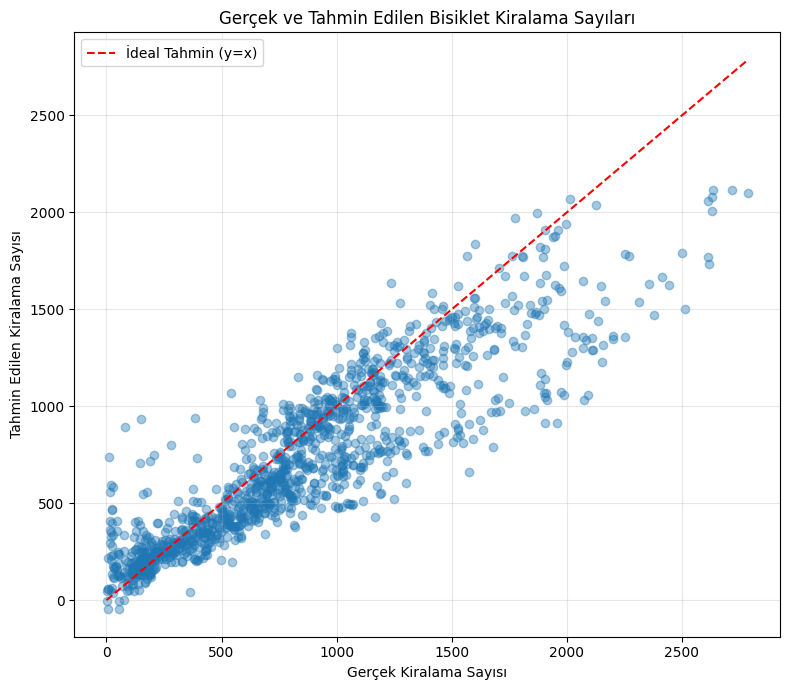

In [22]:

# Gerçek ve tahmin edilen kiralama sayılarını karşılaştırma
plt.figure(figsize=(8, 7))

plt.scatter(
    y_test,
    y_test_pred,
    alpha=0.4
)

# İdeal tahmin doğrusu (y = x)
max_deger = max(y_test.max(), y_test_pred.max())

plt.plot(
    [0, max_deger],
    [0, max_deger],
    color="red",
    linestyle="--",
    label="İdeal Tahmin (y=x)"
)

plt.title("Gerçek ve Tahmin Edilen Bisiklet Kiralama Sayıları")
plt.xlabel("Gerçek Kiralama Sayısı")
plt.ylabel("Tahmin Edilen Kiralama Sayısı")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()



#### 6.2.1. Gerçek ve Tahmin Edilen Değerler - Bulgular ve Yorum

Gerçek ve tahmin edilen bisiklet kiralama sayılarının karşılaştırıldığı grafikte, gözlemlerin önemli bir bölümünün ideal tahmin doğrusuna yakın konumlandığı görülmektedir.

Bununla birlikte modelin özellikle düşük kiralama sayılarında gerçek değerlerden daha yüksek tahminler yaptığı bazı gözlemler bulunmaktadır.

Yüksek kiralama sayılarında ise modelin gerçek değerlerden daha düşük tahminler yapma eğilimi gözlenmektedir.

Bu durum, modelin çok düşük ve çok yüksek talep seviyelerini tahmin etmekte zorlanabildiğini düşündürmektedir.

Grafik, test kümesinde elde edilen MAE ve RMSE değerlerini desteklemekte ve modelin tahmin hatalarının tüm talep seviyelerinde aynı şekilde dağılmadığını göstermektedir.

Bu nedenle sonraki aşamada tahmin hataları artık (residual) analiziyle daha ayrıntılı incelenecektir.



### 6.3. Artık Analizi (Residual Analysis)

Modelin tahmin hatalarını ayrıntılı incelemek amacıyla artık analizi yapılacaktır.

Artık değerleri, gerçek kiralama sayısı ile modelin tahmin ettiği kiralama sayısı arasındaki fark olarak hesaplanmaktadır:

Residual = Gerçek Değer - Tahmin Edilen Değer

Pozitif artıklar modelin eksik tahmin yaptığını, negatif artıklar ise fazla tahmin yaptığını göstermektedir.

Artıkların tahmin edilen değerlere göre dağılımı incelenerek sistematik hata örüntüleri ve hata büyüklüğündeki değişimler değerlendirilecektir.


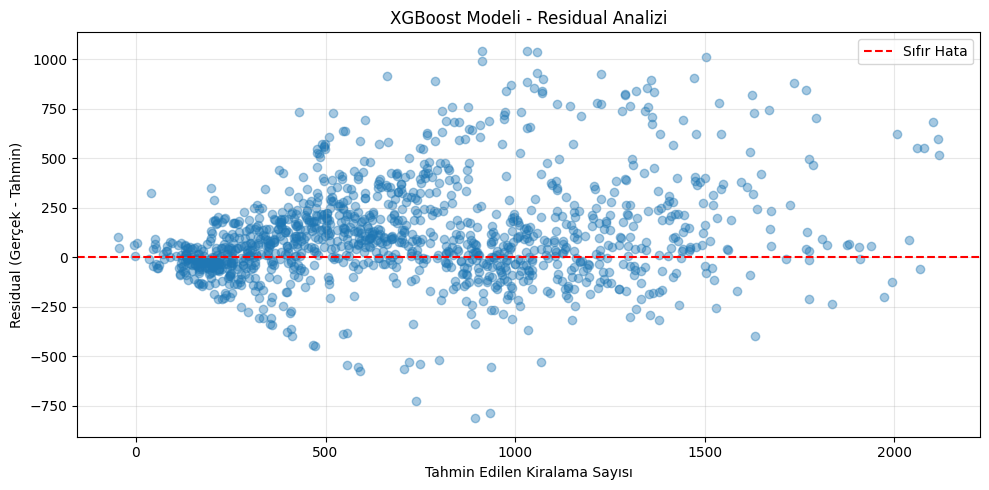

Ortalama residual: 114.43
Residual standart sapması: 249.11
En büyük mutlak hata: 1044.29


In [23]:

# Residual (artık) değerlerini hesaplama
residuals = y_test.to_numpy() - y_test_pred

# Artık grafiği
plt.figure(figsize=(10, 5))

plt.scatter(
    y_test_pred,
    residuals,
    alpha=0.4
)

# Sıfır hata referans çizgisi
plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    label="Sıfır Hata"
)

plt.title("XGBoost Modeli - Residual Analizi")
plt.xlabel("Tahmin Edilen Kiralama Sayısı")
plt.ylabel("Residual (Gerçek - Tahmin)")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Artıkların özet istatistikleri
print("Ortalama residual:", round(residuals.mean(), 2))
print("Residual standart sapması:", round(residuals.std(), 2))
print("En büyük mutlak hata:", round(np.abs(residuals).max(), 2))



#### 6.3.1. Artık Analizi - Bulgular ve Yorum

Nihai XGBoost modelinin test kümesindeki ortalama artık değeri +114,43 olarak hesaplanmıştır. Bu sonuç, modelin ortalama olarak gerçek kiralama sayılarından daha düşük tahmin yapma eğiliminde olduğunu göstermektedir.

Artıkların standart sapması 249,11, en büyük mutlak tahmin hatası ise 1.044,29 olarak bulunmuştur.

Artık grafiğinde hataların sıfır çizgisinin her iki tarafında dağıldığı, ancak tahmin edilen kiralama sayısı arttıkça hata yayılımının genel olarak genişlediği gözlenmektedir.

Bu durum, hata varyansının sabit olmayabileceğini düşündürmektedir. Ayrıca pozitif ortalama artık değeri, test döneminde sistematik eksik tahmin eğilimine işaret etmektedir.

Modelin özellikle bazı gözlemlerde büyük tahmin hataları yaptığı görülmüştür. Bu hataların hangi saatlerde yoğunlaştığı sonraki analizde incelenecektir.



### 6.4. Saatlere Göre Tahmin Hatalarının İncelenmesi

Modelin günün farklı saatlerindeki tahmin performansını değerlendirmek amacıyla test kümesindeki mutlak tahmin hataları saatlere göre gruplandırılacaktır.

Her saat için ortalama mutlak hata (MAE) ve ortalama residual hesaplanacaktır.

Bu analiz, modelin hangi saatlerde daha yüksek tahmin hatası yaptığını ve belirli saatlerde sistematik fazla veya eksik tahmin eğilimi bulunup bulunmadığını incelemeyi amaçlamaktadır.


,Gozlem_Sayisi,MAE,Ortalama_Residual
Hour,,,
0,52,119.43,78.22
1,52,117.85,56.72
2,52,67.70,9.21
3,52,41.48,-7.60
4,52,62.91,-45.33
5,52,50.71,-47.40
6,52,52.25,19.83
7,53,342.15,271.54
8,53,533.77,457.81


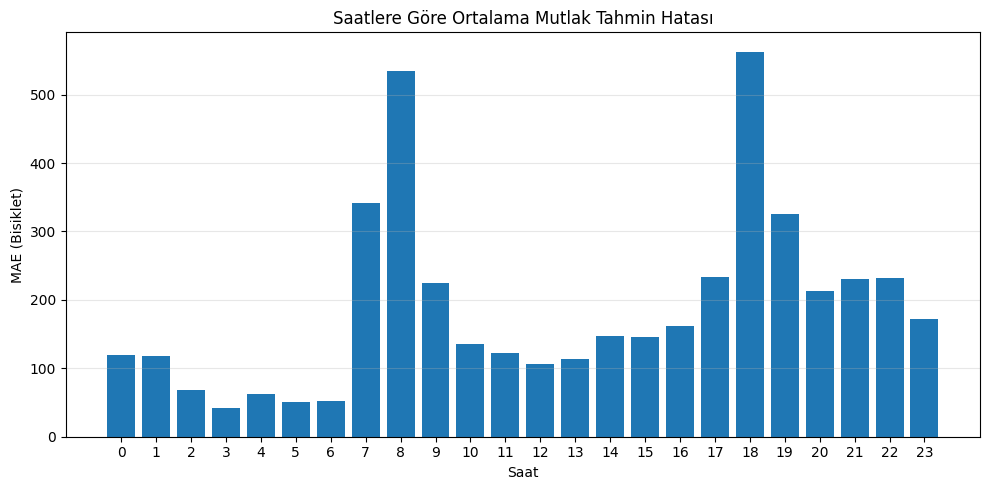

In [24]:

# Test verisindeki tahmin hatalarını tabloya dönüştürme
hata_df = pd.DataFrame({
    "Hour": X_test["Hour"].to_numpy(),
    "Gercek": y_test.to_numpy(),
    "Tahmin": y_test_pred
})

# Residual ve mutlak hata hesaplama
hata_df["Residual"] = hata_df["Gercek"] - hata_df["Tahmin"]
hata_df["Mutlak_Hata"] = hata_df["Residual"].abs()

# Saatlere göre hata istatistikleri
saatlik_hatalar = hata_df.groupby("Hour").agg(
    Gozlem_Sayisi=("Mutlak_Hata", "count"),
    MAE=("Mutlak_Hata", "mean"),
    Ortalama_Residual=("Residual", "mean")
)

display(saatlik_hatalar.round(2))

# Saatlere göre MAE grafiği
plt.figure(figsize=(10, 5))

plt.bar(
    saatlik_hatalar.index,
    saatlik_hatalar["MAE"]
)

plt.title("Saatlere Göre Ortalama Mutlak Tahmin Hatası")
plt.xlabel("Saat")
plt.ylabel("MAE (Bisiklet)")
plt.xticks(range(24))
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()



#### 6.4.1. Saatlik Hata Analizi - Bulgular ve Yorum

Test kümesindeki tahmin hataları saatlere göre incelendiğinde, en yüksek ortalama mutlak hataların saat 18.00 (MAE = 562,82) ve 08.00'de (MAE = 533,77) gerçekleştiği görülmüştür.

Bu saatlerde ortalama residual değerleri sırasıyla +542,39 ve +457,81 olarak hesaplanmıştır. Pozitif residual değerleri, modelin özellikle yoğun kiralama saatlerinde gerçek kiralama sayılarını olduğundan düşük tahmin etme eğiliminde olduğunu göstermektedir.

En düşük MAE değerleri ise 03.00 (41,48), 05.00 (50,71) ve 06.00 (52,25) saatlerinde gözlenmiştir.

Veri keşfi aşamasında kiralama sayılarının özellikle 08.00 ve 18.00 saatlerinde yoğunlaştığı belirlenmişti. Hata analizinde de en yüksek tahmin hatalarının aynı saatlerde görülmesi, modelin yoğun talep dönemlerini tahmin etmekte zorlanabildiğini düşündürmektedir.

Bununla birlikte düşük kiralama seviyelerinde MAE'nin küçük olması, oransal tahmin hatasının da mutlaka düşük olduğu anlamına gelmemektedir.

Sonuç olarak modelin en önemli geliştirme alanlarından biri, yoğun kiralama saatlerinde ortaya çıkan sistematik eksik tahmin eğilimidir.



### 6.5. Değişken Önemlerinin İncelenmesi (Feature Importance)

Nihai XGBoost modelinin tahminlerinde hangi değişkenlerden daha fazla yararlandığını belirlemek amacıyla Feature Importance analizi yapılacaktır.

Değişken önemleri, XGBoost modelinin karar ağaçlarında kullanılan ayrımların toplam kazancını ifade eden Total Gain yöntemiyle hesaplanacaktır.

Bu analiz, modelin tahminlerini oluştururken hangi özelliklerden daha fazla yararlandığını incelemeyi amaçlamaktadır.

Değişken önemleri nedensel etkiyi göstermemekte, yalnızca eğitilmiş modelin iç yapısına ilişkin bilgi sağlamaktadır.


En önemli 10 değişken:


,Önem (%)
Temperature,39.29
Hour,30.95
Solar Radiation,8.18
Humidity,7.09
Rainfall,4.27
Dew point temperature,3.96
DayOfWeek,3.81
Month,1.08
Holiday_Holiday,0.34
Seasons_Spring,0.31


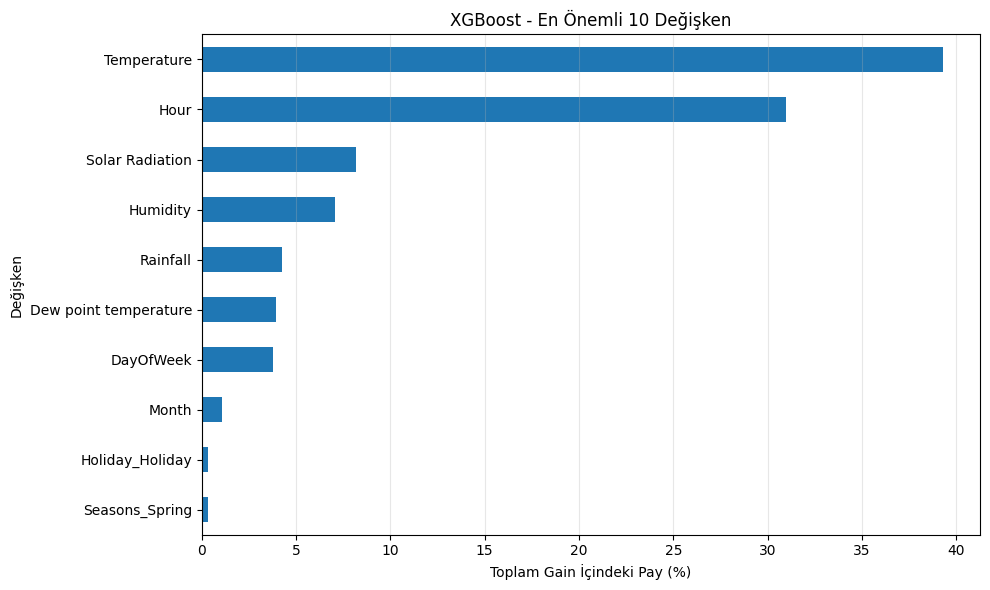

In [25]:

# Nihai XGBoost modelinden değişken önemlerini alma
importance_dict = final_model.get_booster().get_score(
    importance_type="total_gain"
)

# Bütün girdi değişkenlerini içeren tablo oluşturma
importance = pd.Series(importance_dict).reindex(
    X_train_val.columns,
    fill_value=0
)

# Toplam öneme göre normalize etme
importance_pct = (importance / importance.sum()) * 100

# Önem sırasına göre sıralama
importance_pct = importance_pct.sort_values(ascending=False)

# En önemli 10 değişken
print("En önemli 10 değişken:")
display(importance_pct.head(10).to_frame("Önem (%)").round(2))

# Grafik
plt.figure(figsize=(10, 6))

importance_pct.head(10).sort_values().plot(
    kind="barh"
)

plt.title("XGBoost - En Önemli 10 Değişken")
plt.xlabel("Toplam Gain İçindeki Pay (%)")
plt.ylabel("Değişken")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()



#### 6.5.1. Değişken Önemleri - Bulgular ve Yorum

XGBoost modelinin Total Gain yöntemiyle hesaplanan değişken önemleri incelendiğinde, en yüksek öneme sahip değişkenlerin Temperature (%39,29) ve Hour (%30,95) olduğu görülmüştür.

Bu iki değişken birlikte modelin toplam gain değerinin %70,24'ünü oluşturmaktadır.

Diğer önemli değişkenler arasında Solar Radiation (%8,18), Humidity (%7,09), Rainfall (%4,27) ve Dew point temperature (%3,96) bulunmaktadır.

Bu sonuçlar, veri keşfi aşamasında sıcaklık ve saat değişkenleriyle kiralama sayısı arasında gözlenen ilişkileri desteklemektedir.

Bununla birlikte saat değişkeninin yüksek önem taşımasına rağmen modelin özellikle 08.00 ve 18.00 saatlerinde yüksek tahmin hataları yaptığı belirlenmiştir.

Mevsim ve tatil değişkenlerinin görece düşük önem değerleri, bu değişkenlerin etkisiz olduğu anlamına gelmemektedir. Özellikle birbiriyle ilişkili değişkenler model içerisinde benzer bilgileri temsil edebilir.

Feature Importance sonuçları nedensel etki olarak değil, eğitilmiş modelin değişkenlerden yararlanma düzeyi olarak yorumlanmıştır.



## 7. Sonuç ve Geliştirme Önerileri

Bu projede Seoul Bike Sharing Demand veri seti kullanılarak saatlik bisiklet kiralama sayılarını tahmin eden bir XGBoost regresyon modeli geliştirilmiştir.

Veri keşfi, ön işleme, model eğitimi ve hiperparametre karşılaştırması aşamalarının ardından nihai model 7.200 gözlemle eğitilmiş ve 1.265 gözlemden oluşan test kümesinde değerlendirilmiştir.

### 7.1. Modelin Güçlü Yönleri

Nihai modelin test performansı MAE = 188,83, RMSE = 274,13 ve R² = 0,7531 olarak hesaplanmıştır.

Bu sonuçlar, modelin test dönemindeki kiralama sayılarını tahmin etmede anlamlı bir performans gösterdiğini ortaya koymaktadır.

Değişken önemleri analizinde sıcaklık ve saat bilgileri en önemli özellikler olarak belirlenmiştir. Modelin zaman ve meteorolojik koşullarla ilişkili örüntülerden yararlanabildiği görülmüştür.

### 7.2. Modelin Zayıf Yönleri ve Sınırlılıkları

Hata analizinde modelin özellikle 08.00 ve 18.00 saatlerinde gerçek kiralama sayılarını olduğundan düşük tahmin etme eğiliminde olduğu belirlenmiştir.

Test kümesinde ortalama residual +114,43 olarak hesaplanmış, bu da genel bir eksik tahmin eğilimine işaret etmiştir.

Veri setinin yalnızca bir yıllık olması ve test kümesinin sadece sonbahar dönemini kapsaması, sonuçların diğer dönemlere genellenmesini sınırlandırmaktadır.

Ayrıca model, sistemin çalıştığı saatlerde gerçekleşen kiralama sayılarını tahmin etmektedir. Karşılanamayan talep doğrudan gözlemlenmediğinden model çıktıları gerçek talebin eksiksiz ölçümü olarak değerlendirilmemelidir.

### 7.3. Geliştirme Önerileri

Gelecekte birden fazla yıla ait veri kullanılarak mevsimsel değişimlerin daha kapsamlı öğrenilmesi sağlanabilir.

Yoğun saatlerdeki tahmin hatalarını azaltmak amacıyla zaman değişkenleriyle ilgili ek özellikler üretilebilir veya yoğun saatlere yönelik alternatif modelleme yaklaşımları araştırılabilir.

Modelin farklı dönemlerdeki performansı, ileriye dönük zaman serisi doğrulama yöntemleriyle daha kapsamlı değerlendirilebilir.

Ayrıca daha geniş bir hiperparametre araması ve alternatif regresyon algoritmalarıyla karşılaştırmalar yapılabilir.

### 7.4. Genel Sonuç

XGBoost regresyon modelinin saatlik bisiklet kiralama sayılarını tahmin etmek için kullanılabilir bir yaklaşım olduğu görülmüştür.

Bununla birlikte yoğun saatlerdeki sistematik tahmin hataları ve veri setinin zamansal sınırlılıkları, modelin gerçek operasyonel uygulamalardan önce geliştirilmesi gereken yönlerini oluşturmaktadır.

